In [1]:
import matplotlib.pyplot as plt
import numpy as np

from hnn_core import new_calcium_model, simulate_dipole

from hnn_core.params import compare_dictionaries

from hnn_core.viz import plot_cell_morphology

# import pandas as pd
from scipy import signal
from plot_utils import fig_conductances, fig_compartments
from matplotlib.gridspec import GridSpec
import os
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

pathfig = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_hnn_model/'
#os.mkdir(pathfig)

In [2]:
net = new_calcium_model()
net.clear_connectivity()

net.set_cell_positions(inplane_distance=30.)

depths = list(list(range(-100,2200,200)))
electrode_pos = [(135, 135, dep) for dep in depths]

net.add_electrode_array('probe1', electrode_pos)

ampl = 3.
t0 = 10

for i in range(3):
    net.add_tonic_bias(cell_type='L5_pyramidal',section='soma',bias_name='pulse_'+str(i),amplitude=ampl,t0=t0+i*10,tstop=t0+i*10+3)

dpl = simulate_dipole(net, tstop=100, n_trials=1,record_vsec='all',record_isec='all',record_ca='all')


/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/dipole.py:69: UserWarning: No connections instantiated in network. Consider using net = jones_2009_model() or net = law_2021_model() to create a predefined network from published models.
  warnings.warn('No connections instantiated in network. Consider using '


Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...


In [3]:
timevec = net.cell_response.times

clamp = np.zeros_like(timevec) 

for bias in net.external_biases:
    for cell_type in net.external_biases[bias]:
        t0 = np.argmin(np.abs(timevec - net.external_biases[bias][cell_type]['t0']))
        tstop = np.argmin(np.abs(timevec - net.external_biases[bias][cell_type]['tstop']))

        clamp[t0:tstop] = net.external_biases[bias][cell_type]['amplitude']

In [4]:
I = np.array(net.cell_response.spike_gids[0]) <270
gids = np.array(net.cell_response.spike_gids).reshape(-1,)[I]
times = np.array(net.cell_response.spike_times).reshape(-1,)[I]

l5_first = gids[np.where(((gids > 169).astype(float) + (gids <=270).astype(float)) == 2)[0][0]]
vltg = net.cell_response.vsec[0][int(l5_first)]
ca = net.cell_response.ca[0][int(l5_first)]

l5_gids = gids[np.where(((gids > 169).astype(float) + (gids <=270).astype(float)) == 2)[0]]
l5_unique_gids = np.array([])
for l5 in l5_gids:
    if ~np.isin(l5,l5_unique_gids):
        l5_unique_gids = np.append(l5_unique_gids, l5)

ca_l5_tuft = np.zeros((l5_unique_gids.shape[0], len(net.cell_response.times)))
ca_l5_apcl2 = np.zeros((l5_unique_gids.shape[0], len(net.cell_response.times)))
vltg_l5_soma = np.zeros((l5_unique_gids.shape[0], len(net.cell_response.times)))
ca_l5_soma = np.zeros((l5_unique_gids.shape[0], len(net.cell_response.times)))

for i, g in enumerate(l5_unique_gids.astype(int)):
    ca_l5_tuft[i] = net.cell_response.ca[0][g]['apical_tuft']
    ca_l5_apcl2[i] = net.cell_response.ca[0][g]['apical_2']
    ca_l5_soma[i] = net.cell_response.ca[0][g]['apical_2']
    vltg_l5_soma[i] = net.cell_response.vsec[0][g]['soma']

In [5]:
window_len, scaling_factor = 20, 3000
dpl[0].scale(scaling_factor)

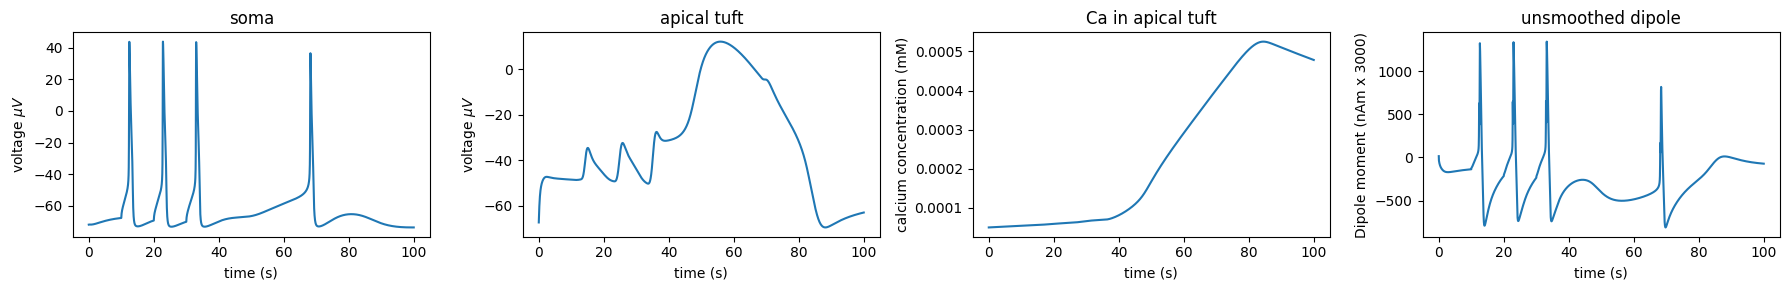

In [6]:
timevec = net.cell_response.times


fig, axs = plt.subplots(1,4,figsize=(18,3))
# v_int2 = net.cell_response.vsec[0][0]['soma']
# plt.plot(timevec, v_int2)
# v_l2 = net.cell_response.vsec[0][35]['soma']
# plt.plot(timevec, v_l2)
# v_int5 = net.cell_response.vsec[0][135]['soma']
# plt.plot(timevec, v_int5)
v_l5 = net.cell_response.vsec[0][170]['soma']
axs[0].plot(timevec, v_l5)
axs[0].set_ylabel('voltage $\mu V$')
axs[0].set_title('soma')
v_l5_apcl = net.cell_response.vsec[0][170]['apical_tuft']
axs[1].plot(timevec, v_l5_apcl)
axs[1].set_ylabel('voltage $\mu V$')
axs[1].set_title('apical tuft')

ca_l5 = net.cell_response.ca[0][170]['apical_tuft']

axs[2].plot(timevec, ca_l5)
axs[2].set_title('Ca in apical tuft')
axs[2].set_ylabel('calcium concentration (mM)')

axs[3].plot(timevec, dpl[0].data['L5'])
axs[3].set_title('unsmoothed dipole')
axs[3].set_ylabel('Dipole moment (nAm x 3000)')

for ax in axs:
    ax.set_xlabel('time (s)')

fig.tight_layout()
fig.savefig(os.path.join(pathfig,'l5_electrophysio.png'))

In [ ]:
dpl[0].smooth(window_len)

In [ ]:

fig, axs = plt.subplots(2,2,figsize=(12,6),height_ratios=[0.25, 1])

axs[0,0].plot(timevec, clamp, color='r')
axs[0,1].plot(timevec, clamp, color='r')

im = axs[1,0].pcolormesh(timevec,np.arange(len(l5_unique_gids)),vltg_l5_soma, shading='gouraud')
axs[1,0].invert_yaxis()
axs[1,0].set_title('soma')
cb = plt.colorbar(im, ax= axs[1,0], orientation='horizontal', shrink=0.5)
cb.set_label('voltage $\mu V$')
cb.set_ticks([-70,0, 40])
ax2 = axs[1,0].twinx()
ax2.plot(timevec,dpl[0].data['agg'], color=(1,1,1), alpha=0.5)
ax2.set_yticks([])

window_len, scaling_factor = 20, 3000

im = axs[1,1].pcolormesh(timevec,np.arange(len(l5_unique_gids)),ca_l5_tuft, shading='gouraud')
axs[1,1].invert_yaxis()
axs[1,1].set_title('tuft')
axs[1,1].set_xlabel('time (s)')
axs[1,0].set_xlabel('time (s)')

axs[1,0].set_ylabel('L5 pyr neuron idx')
cb = plt.colorbar(im, ax= axs[1,1], orientation='horizontal', shrink=0.5)
cb.set_label('calcium concentration mM')
ax2 = axs[1,1].twinx()
ax2.plot(timevec,dpl[0].data['agg'], color=(1,1,1), alpha=0.5)
ax2.set_yticks([])



fig.tight_layout()

fig.savefig(os.path.join(pathfig,'l5_network_rsp.png'))

In [22]:
from hnn_core.extracellular import _get_laminar_z_coords

contact_labels, delta = _get_laminar_z_coords(net.rec_arrays['probe1'][0].positions)

In [ ]:
fig, axs = plt.subplots(2,3, figsize=(12,6), width_ratios=[0.2, 1, 1])

sections = ['soma', 'apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
L = []
for section in sections:
    L.append(net.cell_types["L5_pyramidal"].sections[section].L)

prevL = 0
for i, section in enumerate(sections):
    axs[0,0].plot(np.zeros(int(L[i]),), np.arange(0, L[i], 1)+prevL, linewidth=2, label=section)
    axs[1,0].plot(np.zeros(int(L[i]),), np.arange(0, L[i], 1)+prevL, linewidth=2, label=section)

    v = np.array(net.cell_response.vsec[0][171][section])
    axs[0,1].plot(timevec, v + i*110)
    ca = np.array(net.cell_response.ca[0][171][section])
    axs[0,2].plot(timevec, ca + i*0.0003)
    prevL += L[i]


axs[0,0].set_xticks([])
axs[1,0].set_xticks([])
axs[0,1].set_title('membrane potential')
axs[0,2].set_title('calcium concentration')

new_ticks = contact_labels[0:len(contact_labels):2]
axs[1,0].set_yticks(new_ticks)

net.rec_arrays['probe1'][0].smooth(window_len).plot_lfp(ax=axs[1,1], show=False)
lfp_ticks = axs[1,1].get_yticks()
lfp_ticks = lfp_ticks[0:-1:2]

axs[1,1].set_yticks(lfp_ticks)
axs[1,1].set_ylim([lfp_ticks[0], lfp_ticks[-1]+50])
axs[1,1].set_xlabel('time (s)')
axs[1,1].set_title('LFP')

net.rec_arrays['probe1'][0].smooth(window_len).plot_csd(ax=axs[1,2], show=False, vmin=-0.002, vmax=0.002)
axs[1,2].set_yticks(new_ticks)
axs[1,2].set_title('CSD')
axs[1,2].set_ylim((-100, 2100))
axs[1,0].set_ylim(axs[1,2].get_ylim())

fig.tight_layout()
fig.savefig(os.path.join(pathfig,'l5_lfp_csd.png'))
#fig.savefig(os.path.join(pathfig,'l5_lfp_csd.svg'))



In [ ]:
net.rec_arrays['probe1'].voltages

In [ ]:
net_no_ca = new_calcium_model()
net_no_ca.clear_connectivity()

# block Ca
# 
net_no_ca.cell_types['L5_pyramidal'].sections['soma'].mechs['Ca_HVA']['gbar_Ca_HVA'] = 0
net_no_ca.cell_types['L5_pyramidal'].sections['soma'].mechs['Ca_LVAst']['gbar_Ca_LVAst'] = 0

sections = ['apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
for section in sections:
    net_no_ca.cell_types['L5_pyramidal'].sections[section].mechs['Ca_LVAst']['gbar_Ca_LVAst'][1] = np.zeros_like(net_no_ca.cell_types['L5_pyramidal'].sections[section].mechs['Ca_LVAst']['gbar_Ca_LVAst'][1])


net_no_ca.set_cell_positions(inplane_distance=30.)

depths = list(list(range(-100,2200,200)))
electrode_pos = [(135, 135, dep) for dep in depths]

net_no_ca.add_electrode_array('probe1', electrode_pos)

ampl = 3.
t0 = 10

for i in range(3):
    net_no_ca.add_tonic_bias(cell_type='L5_pyramidal',section='soma',bias_name='pulse_'+str(i),amplitude=ampl,t0=t0+i*10,tstop=t0+i*10+3)

dpl_no_ca = simulate_dipole(net_no_ca, tstop=100, n_trials=1,record_vsec='all',record_isec='all',record_ca='all')

window_len, scaling_factor = 20, 3000
dpl_no_ca[0].smooth(window_len).scale(scaling_factor)


In [ ]:
fig, ax = plt.subplots()
ax.plot(timevec, dpl[0].data['L5'], color='k')
ax.plot(timevec, dpl_no_ca[0].data['L5'], color=[0.5, 0.5, 0.5])

ax.set_title('smoothed dipole')
ax.set_ylabel('dipole (nAm x 3000)')
ax.set_xlabel('time (s)')
fig.savefig(os.path.join(pathfig,'dipole.png'))


In [ ]:
net = new_calcium_model()
net.clear_connectivity()

net.set_cell_positions(inplane_distance=30.)

depths = list(list(range(-100,2200,200)))
electrode_pos = [(135, 135, dep) for dep in depths]

net.add_electrode_array('probe1', electrode_pos)

ampl = 2.5
t0 = 10

for i in range(3):
    net.add_tonic_bias(cell_type='L5_pyramidal',section='soma',bias_name='pulse_'+str(i),amplitude=ampl,t0=t0+i*25,tstop=t0+i*25+3)

dpl = simulate_dipole(net, tstop=100, n_trials=1,record_vsec='all',record_isec='all',record_ca='all')

timevec = net.cell_response.times


fig, axs = plt.subplots(1,4,figsize=(18,3))

v_l5 = net.cell_response.vsec[0][170]['soma']
axs[0].plot(timevec, v_l5)
axs[0].set_ylabel('voltage $\mu V$')
axs[0].set_title('soma')
v_l5_apcl = net.cell_response.vsec[0][170]['apical_tuft']
axs[1].plot(timevec, v_l5_apcl)
axs[1].set_ylabel('voltage $\mu V$')
axs[1].set_title('apical tuft')

ca_l5 = net.cell_response.ca[0][170]['apical_tuft']

axs[2].plot(timevec, ca_l5)
axs[2].set_title('Ca in apical tuft')
axs[2].set_ylabel('calcium concentration (mM)')

axs[3].plot(timevec, dpl[0].data['L5'])
axs[3].set_title('unsmoothed dipole')
axs[3].set_ylabel('Dipole moment (nAm x 3000)')

for ax in axs:
    ax.set_xlabel('time (s)')

fig.tight_layout()
fig.savefig(os.path.join(pathfig,'critfreq.png'))
